# Example of the `aitlas` toolbox in the context of multi class image classification

This notebook shows a sample implementation of a multi class image classification using the `aitlas` toolbox and the Eurosat dataset.

In [ ]:
from aitlas.datasets import EurosatDataset
from aitlas.models import ResNet50
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor
from aitlas.utils import image_loader

## Load the dataset

In [5]:
dataset_config = {
    "data_dir": "/home/dragik/data/EuroSAT/EuroSAT_RGB/",
    "csv_file": "/home/dragik/data/EuroSAT/eurosat_train.csv"
    }
dataset = EurosatDataset(dataset_config)

## Show images from the dataset

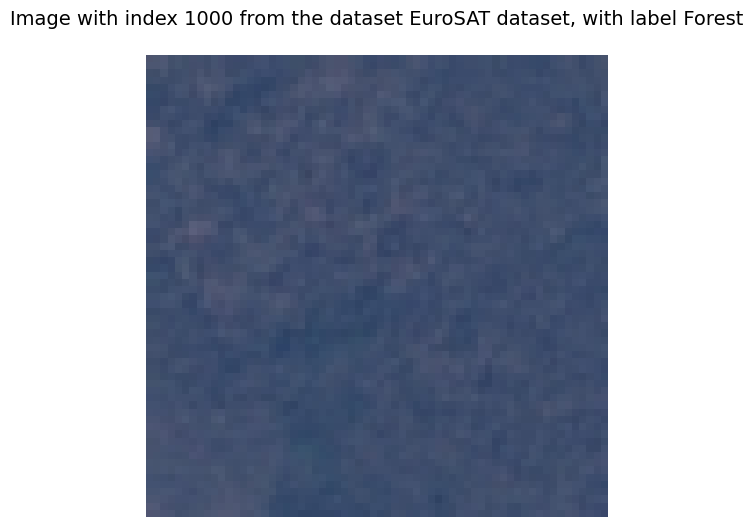

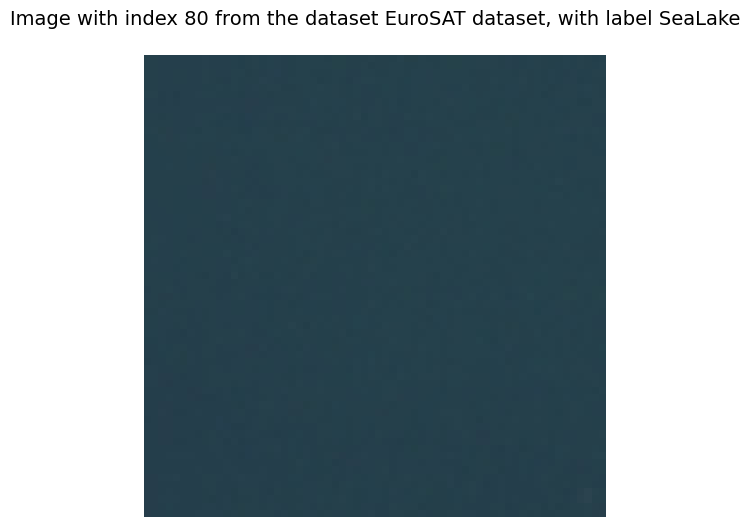

In [6]:
fig1 = dataset.show_image(1000)
fig2 = dataset.show_image(80)

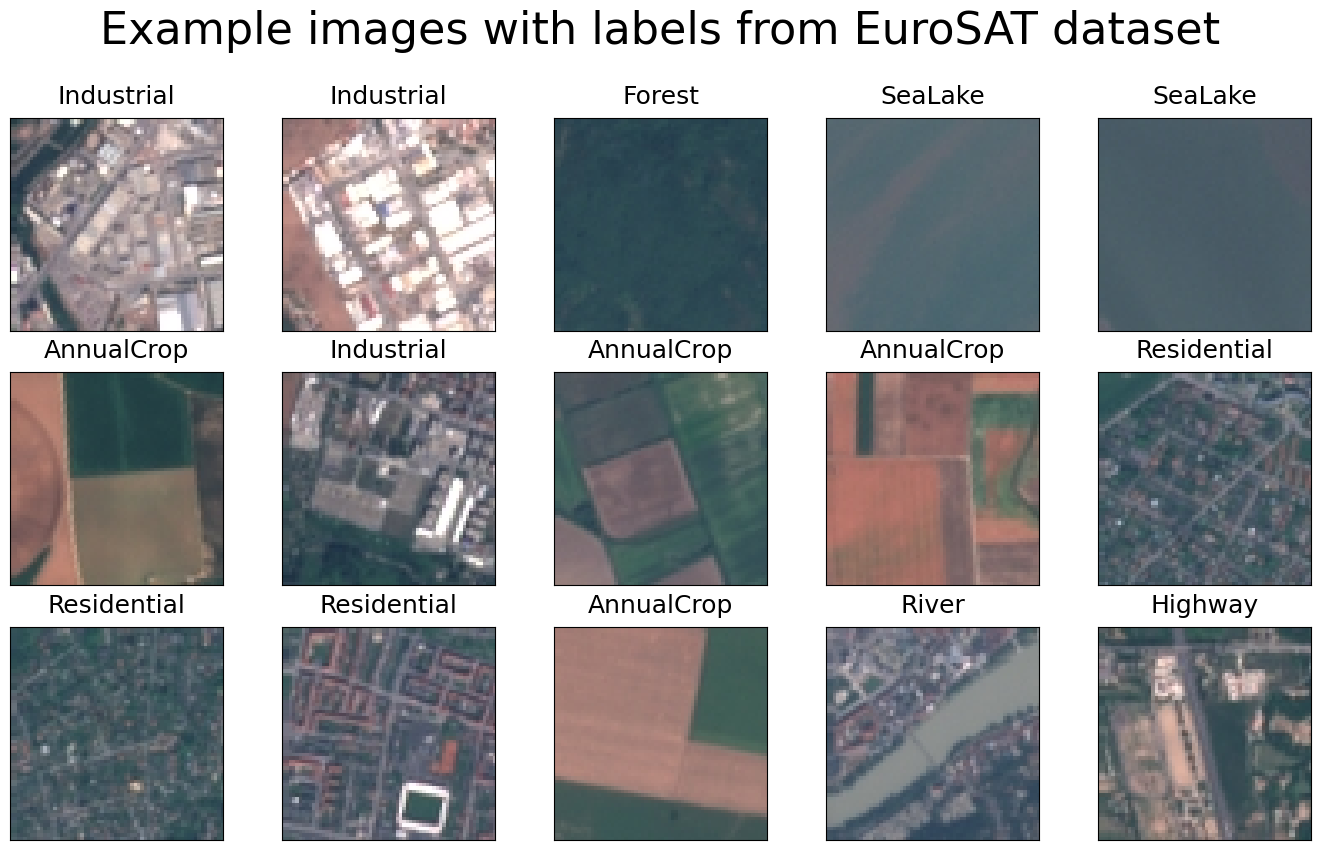

In [7]:
fig3 = dataset.show_batch(15)

## Inspect the data

In [8]:
dataset.show_samples()

,File name,Label
0,Forest/Forest_1523.jpg,Forest
1,SeaLake/SeaLake_1525.jpg,SeaLake
2,SeaLake/SeaLake_2905.jpg,SeaLake
3,River/River_679.jpg,River
4,Residential/Residential_425.jpg,Residential
5,HerbaceousVegetation/HerbaceousVegetation_294.jpg,HerbaceousVegetation
6,AnnualCrop/AnnualCrop_1172.jpg,AnnualCrop
7,Forest/Forest_1541.jpg,Forest
8,Industrial/Industrial_1154.jpg,Industrial
9,HerbaceousVegetation/HerbaceousVegetation_2976...,HerbaceousVegetation


In [9]:
dataset.data_distribution_table()

,Label,Count
0,AnnualCrop,1800
1,Forest,1800
2,HerbaceousVegetation,1800
3,Highway,1500
4,Industrial,1500
5,Pasture,1200
6,PermanentCrop,1500
7,Residential,1800
8,River,1500
9,SeaLake,1800


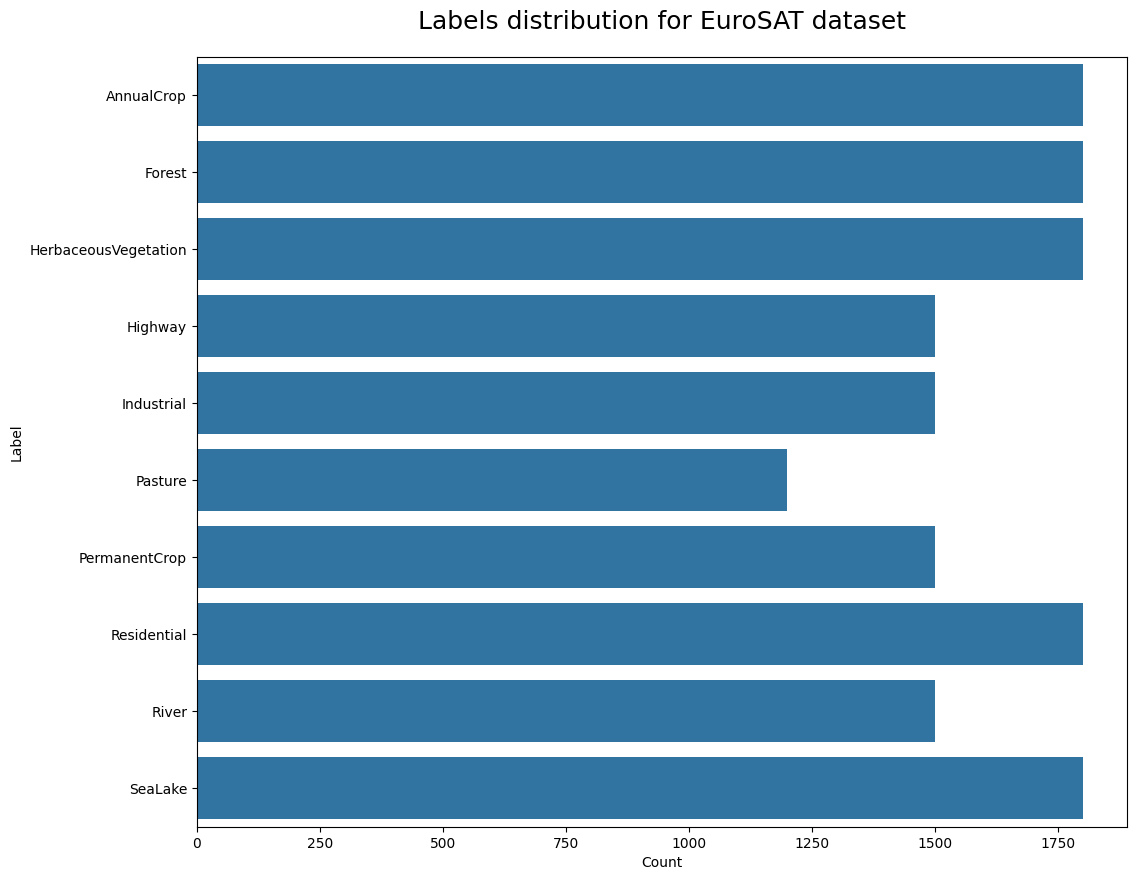

In [10]:
fig = dataset.data_distribution_barchart()

## Load train and test splits

In [11]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/EuroSAT/EuroSAT_RGB/",
    "csv_file": "/home/dragik/data/EuroSAT/eurosat_train.csv"
}

train_dataset = EurosatDataset(train_dataset_config)
train_dataset.transform = ResizeCenterCropFlipHVToTensor()

test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/EuroSAT/EuroSAT_RGB/",
    "csv_file": "/home/dragik/data/EuroSAT/eurosat_val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"],
}

test_dataset = EurosatDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(16200, 5400)

## Setup and create the model for training

In [12]:
epochs = 10
model_directory = "/home/dragik/data/experiments/eurosat"
model_config = {
    "num_classes": 10,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"],
}
model = ResNet50(model_config)
model.prepare()

## Training and evaluation

In [13]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=test_dataset,
    run_id="1",
)

2026-08-24 07:45:00,018 INFO Starting training.
training: 100%|██████████| 1013/1013 [00:54<00:00, 18.48it/s]
2026-08-24 07:45:54,913 INFO epoch: 1, time: 54, loss:  0.46593
testing on train set: 100%|██████████| 1013/1013 [00:25<00:00, 39.79it/s]
2026-08-24 07:46:21,103 INFO Accuracy:0.9658024691358025, Precision Micro:0.9658024691358025, Precision Macro:0.9661009127650946, Precision Weighted:0.9664982270322604, Precision per Class:[0.96871445 0.98133919 0.94002181 0.9589309  0.99454669 0.98565022
 0.89981215 0.99214366 0.95056032 0.98928974], Recall Micro:0.9658024691358025, Recall Macro:0.9642944444444443, Recall Weighted:0.9658024691358025, Recall per Class:[0.94611111 0.99333333 0.95777778 0.98066667 0.97266667 0.91583333
 0.958      0.98222222 0.96133333 0.975     ], F1_score Micro:0.9658024691358019, F1_score Macro:0.9649180187031046, F1_score Weighted:0.9659090320928303, F1_score per Class:[0.95727937 0.98729983 0.94881673 0.96967699 0.983485   0.94946004
 0.92799483 0.98715801

0.07941871568491614

## Predictions

2026-08-24 08:08:50,582 INFO Loading checkpoint /home/dragik/data/experiments/eurosat/checkpoint.pth.tar
2026-08-24 08:08:51,057 INFO Loaded checkpoint /home/dragik/data/experiments/eurosat/checkpoint.pth.tar at epoch 11


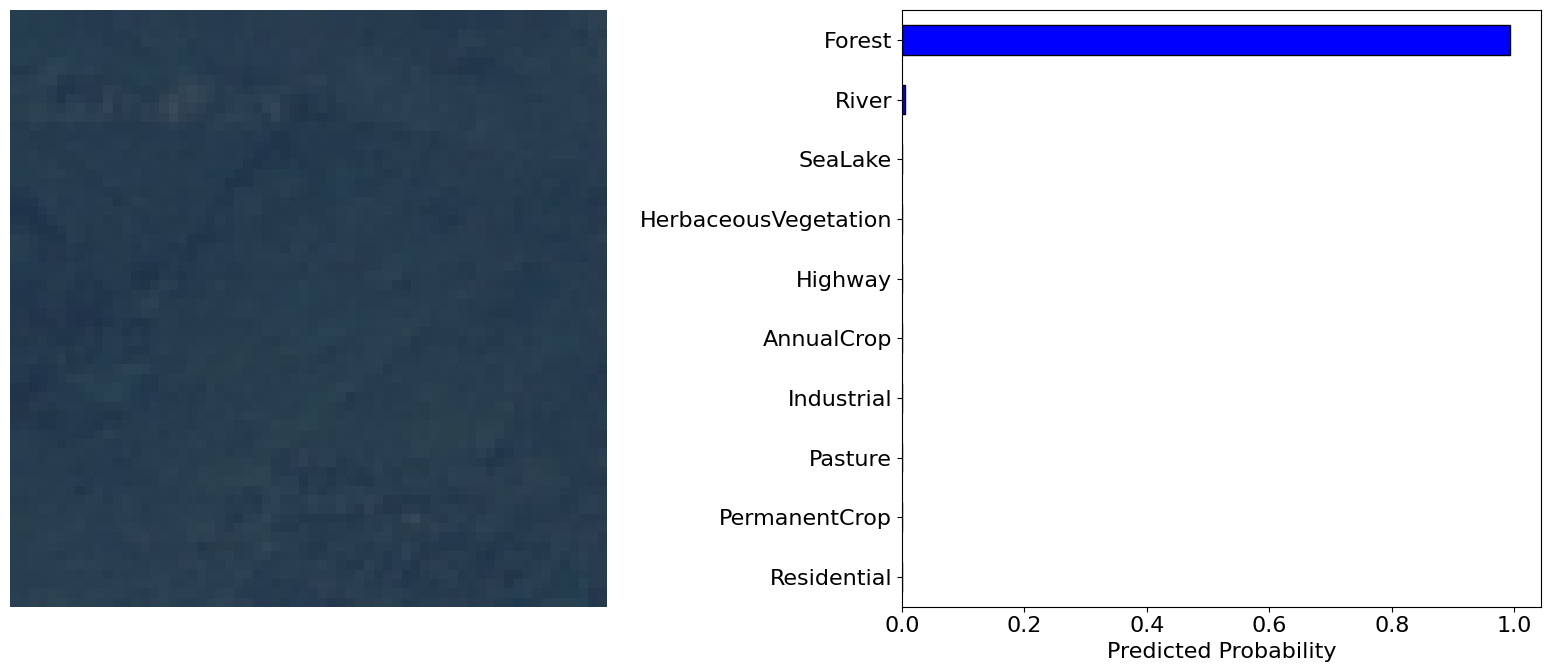

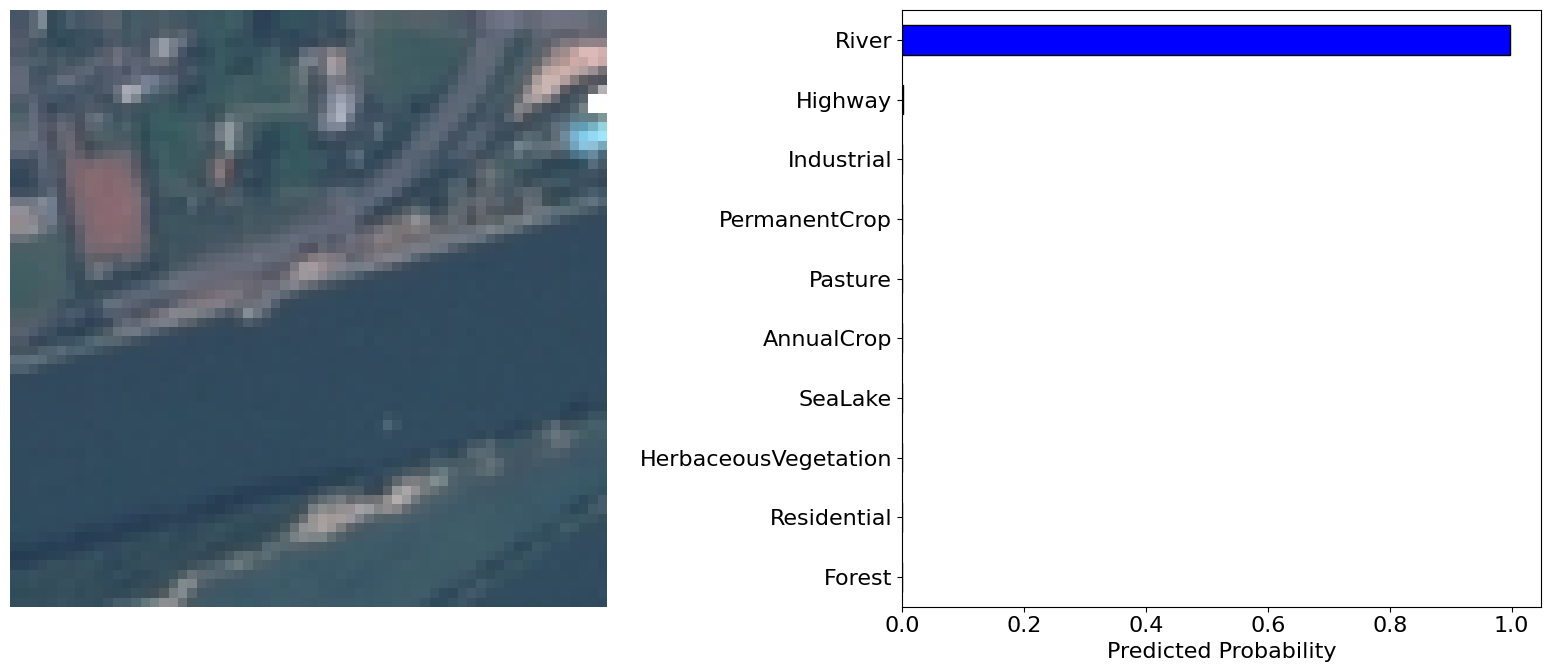

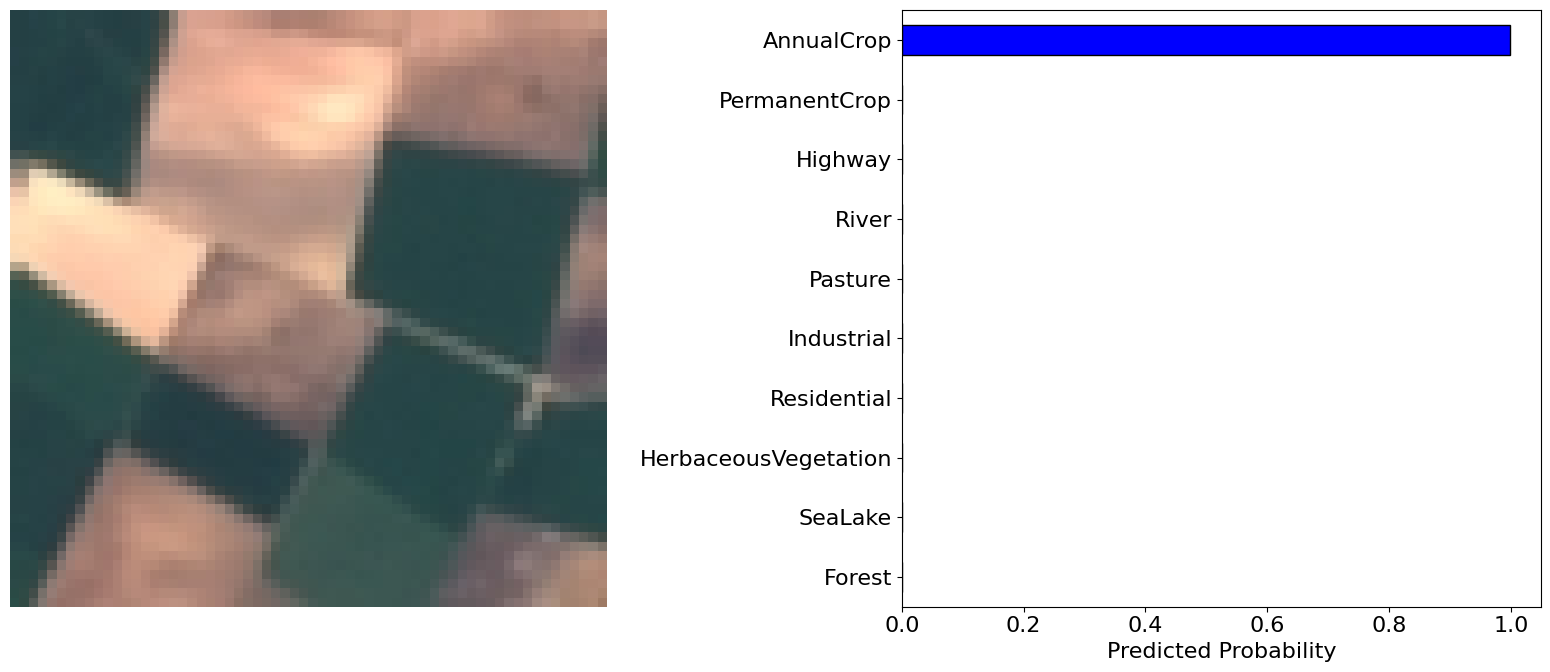

In [14]:
model_path = "/home/dragik/data/experiments/eurosat/checkpoint.pth.tar"
labels = [
    "AnnualCrop",
    "Forest",
    "HerbaceousVegetation",
    "Highway",
    "Industrial",
    "Pasture",
    "PermanentCrop",
    "Residential",
    "River",
    "SeaLake",
]
transform = ResizeCenterCropToTensor()
model.load_model(model_path)

image = image_loader("/home/dragik/data/EuroSAT/EuroSAT_RGB/Forest/Forest_1462.jpg")
fig = model.predict_image(image, labels, transform)

image = image_loader("/home/dragik/data/EuroSAT/EuroSAT_RGB/River/River_1249.jpg")
fig = model.predict_image(image, labels, transform)

image = image_loader("/home/dragik/data/EuroSAT/EuroSAT_RGB/AnnualCrop/AnnualCrop_2910.jpg")
fig = model.predict_image(image, labels, transform)